# FewNake — หลักฐานการเรียนรู้ของโมเดล (Learning Evidence)

**โปรเจกต์:** Thai Fake News Detection (FewNake) · วิชา 240-318 AI & ML
**ไฟล์นี้ทำอะไร:** รันข้อมูลจริง + โมเดลจริงของโปรเจกต์ แล้วแสดง **หลักฐานว่าโมเดล "เรียนรู้จริง"** ในรูปแบบเดียวกับ `Assignment4-6710110343.ipynb`
**อ่านยังไง:** ทุกช่องมีผลลัพธ์ฝังอยู่แล้ว (ไม่ต้องกดรันก็เห็น) — โค้ดช่องไหน ผลช่องนั้น

| ส่วน | หัวข้อ | เทียบกับ Assignment 4 |
|---|---|---|
| 1 | สำรวจข้อมูล | cell 4–5 (EDA) |
| 2 | แบ่ง train/test | cell 7 |
| 3 | **ตัวเทียบไร้สมอง (เส้นฐาน)** | cell 10–11 (ก่อนเทรน 9.69%) |
| 4 | เทรน 3 โมเดล + 5-fold CV | cell 15 (log ต่อ epoch) |
| 5 | **กราฟ learning curve** | cell 17 (learning curve) |
| 6 | **ก่อน → หลัง + เคสที่ทายผิด** | cell 19–21 |
| 7 | ตรวจของที่เสิร์ฟจริง (reload + tokenizer) | cell 23 (save → reload) |
| 8 | สรุปตัวเลขทั้งหมด | cell 24 |

> **SEED = 343** (ตามที่กำหนด) — ของที่ ship อยู่ใน `results/evaluation_results.json` เทรนด้วย **seed 42** จึงต่างกันเล็กน้อยเป็นเรื่องปกติ
> **ไฟล์นี้ไม่เขียนอะไรลงโปรเจกต์เลย** (อ่าน `data/` และ `models/` อย่างเดียว) ผลทั้งหมดอยู่ในตัวไฟล์ `.ipynb` นี้เอง
>
> **หมายเหตุเล็ก ๆ:** ตัวอักษรไทยบนกราฟวาดด้วย matplotlib ซึ่งไม่จัดตำแหน่งสระ/วรรณยุกต์ซ้อนกันเต็มรูปแบบเหมือนโปรแกรมอื่น (ไม่มี Thai text shaping) — อ่านได้ครบทุกตัว แต่ตำแหน่งวรรณยุกต์ในบางคำอาจดูเยื้องเล็กน้อย ตัวอักษรในช่องข้อความ/โค้ดถูกต้องทุกตัว
>
> **ถ้าเปิด/รันบนเครื่องอื่น** (คนละเวอร์ชัน scikit-learn/pythainlp): ตัวเลขอาจต่างจากที่ฝังไว้เล็กน้อย — เท่าที่วัดได้ single-split แกว่งได้ ±1–3 จุด (seed 42 ≈ 0.894 · seed 343 ≈ 0.90)
> ให้อ้างตัวเลขจาก **การรันชุดเดียวกันทั้งเล่ม** ห้ามผสมตัวเลขจากสองเครื่อง/สองรอบ
> ถ้า kernel ที่ใช้ไม่มี `pythainlp` ระบบจะข้ามการทดสอบ tokenizer (ส่วนที่ 7) และพิมพ์คำสั่งติดตั้งให้ในช่องที่ 0


In [1]:
# ============ 0. ตั้งค่า ============
%matplotlib inline
import json, random, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 343
random.seed(SEED)
np.random.seed(SEED)

def find_root(start=None):
    p = (start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / "src" / "train_baseline.py").exists():
            return cand
    raise SystemExit("หา root ของโปรเจกต์ไม่เจอ (เปิดไฟล์จากในโฟลเดอร์ FewNake)")

ROOT = find_root()
sys.path.insert(0, str(ROOT))

# --- ฟอนต์ไทย: หาให้เจอทั้งบน Windows / WSL / Linux (ไม่งั้นตัวอักษรไทยบนกราฟเป็นกล่องเปล่า) ---
import os
import warnings
from matplotlib import font_manager
warnings.filterwarnings("ignore", message="Glyph .* missing from font")

WIN = os.environ.get("WINDIR", "C:/Windows")
THAI_FONTS = [
    # Windows (รันบน Windows ตรง ๆ)
    f"{WIN}/Fonts/leelawui.ttf", f"{WIN}/Fonts/tahoma.ttf",
    # WSL (มองฟอนต์ของ Windows ผ่าน /mnt)
    "/mnt/c/Windows/Fonts/leelawui.ttf", "/mnt/c/Windows/Fonts/tahoma.ttf",
    # Linux
    "/usr/share/fonts/opentype/tlwg/Loma.otf", "/usr/share/fonts/truetype/tlwg/Garuda.ttf",
    "/usr/share/fonts/truetype/tlwg/Norasi.ttf",
    "/usr/share/fonts/truetype/noto/NotoSansThai-Regular.ttf",
    # macOS
    "/System/Library/Fonts/Supplemental/Ayuthaya.ttf", "/Library/Fonts/Tahoma.ttf",
]
# เผื่อไม่เจอตามพาธ: ค้นตามชื่อฟอนต์ที่ matplotlib รู้จักอยู่แล้ว
_NAME_KEYS = ("thai", "leelawadee", "tahoma", "loma", "garuda", "norasi", "ayuthaya")
for _f in font_manager.fontManager.ttflist:
    if any(k in _f.name.lower() for k in _NAME_KEYS):
        THAI_FONTS.append(_f.fname)

font_used = None
for _f in dict.fromkeys(THAI_FONTS):
    if _f and Path(_f).exists():
        try:
            font_manager.fontManager.addfont(_f)
            font_used = font_manager.FontProperties(fname=_f).get_name()
            plt.rcParams["font.family"] = font_used
            break
        except Exception:
            continue
plt.rcParams["axes.unicode_minus"] = False
if font_used:
    print(f"font for charts : {font_used}   ({_f})")
else:
    print("font for charts : !! ไม่พบฟอนต์ไทยในเครื่องนี้ -> ตัวอักษรไทยบนกราฟจะขึ้นเป็นกล่องเปล่า")
    print("                  Windows ปกติมีอยู่แล้ว / Linux: sudo apt install fonts-thai-tlwg")

import sklearn
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_recall_fscore_support)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

# ใช้ตัวโหลดข้อมูลของโปรเจกต์เอง (ไม่คัดลอกโค้ดซ้ำ)
from src.train_baseline import load_soda

def md_table(headers, rows):
    out = ["| " + " | ".join(map(str, headers)) + " |",
           "|" + "|".join(["---"] * len(headers)) + "|"]
    for r in rows:
        out.append("| " + " | ".join(map(str, r)) + " |")
    return "\n".join(out)

print("project root :", ROOT)
print(f"SEED         : {SEED}")
print(f"scikit-learn : {sklearn.__version__}   pandas: {pd.__version__}   numpy: {np.__version__}")
try:
    import pythainlp
    print("pythainlp    :", pythainlp.__version__, "  (ใช้ตรวจคำตัดคำตอนเสิร์ฟในส่วนที่ 7)")
except Exception as e:      # noqa: BLE001
    print("pythainlp    : ไม่มี ->", e)
    print("               ส่วนที่ 7 จะข้ามการทดสอบ tokenizer (ส่วนอื่นทำงานปกติ)")
    print('               ถ้าต้องการให้ครบ: "{0}" -m pip install pythainlp'.format(Path(sys.executable)))


font for charts : Leelawadee UI   (/mnt/c/Windows/Fonts/leelawui.ttf)


project root : /mnt/c/Users/monai/Documents/Y3-1/240-318_AI_ML/Mini/FewNake
SEED         : 343
scikit-learn : 1.7.2   pandas: 2.3.3   numpy: 2.2.6
pythainlp    : 5.3.7   (ใช้ตรวจคำตัดคำตอนเสิร์ฟในส่วนที่ 7)


---
## 1. สำรวจข้อมูลก่อนเทรน (EDA)

เทียบกับ Assignment 4 ที่สำรวจรูปร่างภาพ/ช่วงพิกเซล/จำนวนต่อคลาส — ที่นี่สำรวจจำนวนเอกสารต่อคลาสและความยาวข้อความ


เอกสารที่ใช้ได้ (Fact/Fake เท่านั้น) : 3436
  Fact (0) : 1558   Fake (1) : 1878
  สัดส่วน Fake : 0.5466   <- ถ้าเดา Fake ทุกข้อจะถูกประมาณเท่านี้

ความยาวข้อความ (จำนวนคำ):
  min 3 · median 346 · mean 393 · max 4271

ตัวอย่างข้อความ:
  [Fact] เพื่อน ๆ รู้ ไหม ครับ ว่า " การ ล้างมือ " มีความสำคัญ และ มีส่วนช่วย ใน การป้องกัน COVID- 19 ได้ อีกด้วย ตามมา...
  [Fact] เทรนด์ กิ๊บเก๋ ... ป้องกัน โรค ฮัดเช้ยยยย ...!! ช่วงนี้ จะ ไอ จาม ตาม พื้น ที่สาธารณะ ต้อง ตกเป็น เป้าสายตา ขอ...


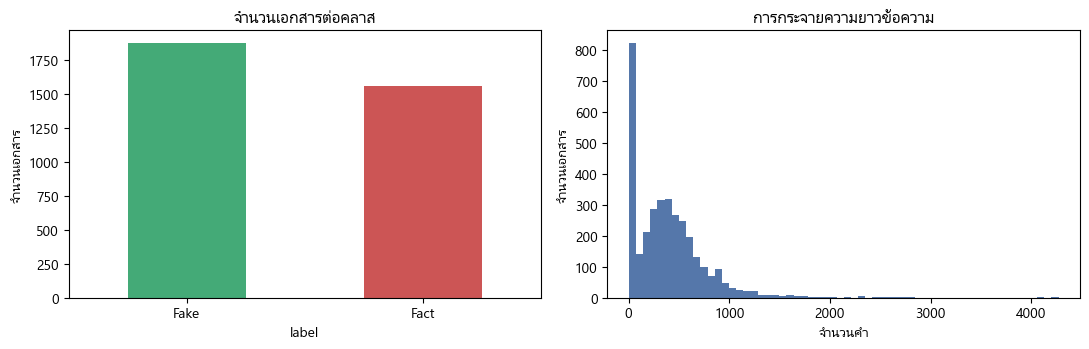

In [2]:
# load_soda() ตัดคำด้วย newmm ตัวเดียวกับที่ API ใช้ -> df["text"] คือข้อความ "แบบที่เสิร์ฟจริง"
# (สวิตช์ load_soda("dataset") คืนคำแบบที่มากับ LimeSoda ไว้ใช้เทียบในส่วนที่ 7)
df = load_soda()
n_tok = df["text"].str.split().str.len()

# ข้อความแบบ "ดิบ" (ไม่มีช่องว่างคั่นคำ) = สิ่งที่ผู้ใช้วางเข้ามาในระบบจริง แล้ว PyThaiNLP ตัดคำเอง
# ใช้ตรวจว่า "คำตัดคำตอนเทรน vs ตอนเสิร์ฟ" ต่างกันแค่ไหน (ดูส่วนที่ 7)
raw_texts, _rows = [], 0
for _name in ("train_v1.jsonl", "val_v1.jsonl", "test_v1.jsonl"):
    for _line in open(ROOT / "data" / _name, encoding="utf-8"):
        _rec = json.loads(_line)
        if _rec.get("Document Tag") not in {"Fact News", "Fake News"}:
            continue
        raw_texts.append("".join(t for t in (_rec.get("Text") or []) if t not in {"", "|||"}))
assert len(raw_texts) == len(df) and raw_texts[0][:20] == df.text[0].replace(" ", "")[:20], "ลำดับข้อมูลไม่ตรงกัน"
print(f"เอกสารที่ใช้ได้ (Fact/Fake เท่านั้น) : {len(df)}")

print(f"  Fact (0) : {int((df.label == 0).sum())}   Fake (1) : {int((df.label == 1).sum())}")
print(f"  สัดส่วน Fake : {(df.label == 1).mean():.4f}   <- ถ้าเดา Fake ทุกข้อจะถูกประมาณเท่านี้")
print()
print("ความยาวข้อความ (จำนวนคำ):")
print(f"  min {n_tok.min()} · median {n_tok.median():.0f} · mean {n_tok.mean():.0f} · max {n_tok.max()}")
print()
print("ตัวอย่างข้อความ:")
for i in [0, 1]:
    print(f"  [{'Fake' if df.label[i] else 'Fact'}] {df.text[i][:110]}...")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
df.label.map({0: "Fact", 1: "Fake"}).value_counts().plot.bar(ax=a1, color=["#4a7", "#c55"], rot=0)
a1.set_title("จำนวนเอกสารต่อคลาส"); a1.set_ylabel("จำนวนเอกสาร")
a2.hist(n_tok, bins=60, color="#57a")
a2.set_title("การกระจายความยาวข้อความ"); a2.set_xlabel("จำนวนคำ"); a2.set_ylabel("จำนวนเอกสาร")
fig.tight_layout(); plt.show()


---
## 2. แบ่งข้อมูล train / test

ใช้วิธีเดียวกับโปรเจกต์ (stratified 80/20) แต่เปลี่ยนเป็น **SEED = 343**
ต่างจาก Assignment 4 ที่มี validation แยกอีก 6,000 ภาพ — โปรเจกต์นี้ใช้ **5-fold CV บน train** ทำหน้าที่เดียวกัน (ดูส่วนที่ 4)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["label"], test_size=0.2, random_state=SEED, stratify=df["label"]
)
print(f"train {len(X_train)} · test {len(X_test)}   (test: Fact {int((y_test == 0).sum())} / Fake {int((y_test == 1).sum())})")

# เอกสารซ้ำเป๊ะที่ตกอยู่ทั้งสองฝั่ง (วัดไว้ ไม่ได้แก้ข้อมูล)
tr_txt, te_txt = set(X_train), set(X_test)
dup_both = tr_txt & te_txt
print(f"ข้อความที่เหมือนกันเป๊ะและอยู่ทั้ง train และ test : {len(dup_both)} ข้อความ")


train 2748 · test 688   (test: Fact 312 / Fake 376)
ข้อความที่เหมือนกันเป๊ะและอยู่ทั้ง train และ test : 14 ข้อความ


---
## 3. ตัวเทียบ "ไร้สมอง" (เส้นฐาน) — ของที่ Assignment 4 เรียกว่า "ก่อนเทรน"

**จุดที่ต้องเข้าใจให้ถูก:** Assignment 4 เทียบโมเดล *น้ำหนักสุ่ม* (ทายได้ 9.69%) เพราะ neural net ทายได้ตั้งแต่ยังไม่เทรน
แต่ FewNake ใช้ Logistic Regression / LinearSVC ซึ่ง **ยังไม่ fit ก็ทายไม่ได้เลย** (จะ error)
ฝั่ง "ก่อนเทรน" จึงต้องใช้ตัวแทนที่ซื่อสัตย์ คือ **กฎไร้สมอง** — ซึ่งจริง ๆ แล้วเป็นเส้นฐานที่ *แข็งกว่า* การเดาสุ่มของ Assignment 4


In [4]:
naive = {}
d = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
p_d = d.predict(X_test)
naive["ทาย Fake ทุกข้อ (majority)"] = (accuracy_score(y_test, p_d), f1_score(y_test, p_d, average="macro"))

p_f = np.zeros(len(y_test), dtype=int)          # ทาย Fact ทุกข้อ
naive["ทาย Fact ทุกข้อ"] = (accuracy_score(y_test, p_f), f1_score(y_test, p_f, average="macro"))

rows = [[k, f"{a:.4f}", f"{f:.4f}"] for k, (a, f) in naive.items()]
rows.append(["เดาสุ่ม 50/50 (ทฤษฎี)", "0.5000", "0.5000"])
print(md_table(["ตัวเทียบไร้สมอง", "accuracy", "macro F1"], rows))


| ตัวเทียบไร้สมอง | accuracy | macro F1 |
|---|---|---|
| ทาย Fake ทุกข้อ (majority) | 0.5465 | 0.3534 |
| ทาย Fact ทุกข้อ | 0.4535 | 0.3120 |
| เดาสุ่ม 50/50 (ทฤษฎี) | 0.5000 | 0.5000 |


---
## 4. เทรนโมเดลจริง (3 แบบ) + 5-fold CV

ใช้สูตรเดียวกับ `src/benchmark.py` เป๊ะ (TF-IDF 10,000 มิติ ngram 1–2 อยู่ใน `Pipeline` → ไม่รั่วข้ามการ fit)
**จุดที่แก้จากโปรเจกต์เดิม:** เลือกโมเดลที่ดีที่สุดด้วย **CV บน train เท่านั้น** ไม่ใช่คะแนน test (ของเดิม `benchmark.py:79-81` เลือกด้วย test → ตัวเลขเอียงขึ้น)


In [5]:
# ใช้ตัวสร้าง TF-IDF ตัวเดียวกับที่โปรเจกต์ใช้ (src/train_baseline.py -> build_vectorizer)
# สำคัญ: tokenizer=str.split + token_pattern=None เพราะข้อความถูกตัดคำมาแล้ว
# และ token_pattern มาตรฐานจะสับคำไทยที่เครื่องหมายวรรณยุกต์ (แพทย์ -> แพทย)
from src.train_baseline import build_vectorizer


def build_pipe(clf):
    return Pipeline([("tfidf", build_vectorizer()), ("clf", clf)])

MODELS = {
    "ComplementNB": ComplementNB(),
    "LogisticRegression (baseline เดิม)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "LinearSVC (calibrated)": CalibratedClassifierCV(LinearSVC(max_iter=2000), cv=3),
}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

fitted, bench = {}, {}
for name, clf in MODELS.items():
    t0 = time.time()
    pipe = build_pipe(clf).fit(X_train, y_train)
    cv = cross_val_score(pipe, X_train, y_train, cv=skf, scoring="f1_macro")
    yp = pipe.predict(X_test)
    acc, f1 = accuracy_score(y_test, yp), f1_score(y_test, yp, average="macro")
    fitted[name] = pipe
    bench[name] = dict(cv_mean=cv.mean(), cv_std=cv.std(), acc=acc, f1=f1,
                       train_sec=time.time() - t0)
    print(f"{name:34s} cv_f1={cv.mean():.4f}±{cv.std():.4f}  test_acc={acc:.4f}  test_f1={f1:.4f}")

best_name = max(bench, key=lambda k: bench[k]["cv_mean"])       # เลือกด้วย CV ไม่ใช่ test
best_by_test = max(bench, key=lambda k: bench[k]["f1"])
best = fitted[best_name]

print()
print(md_table(["โมเดล", "5-fold CV macro F1", "Test Acc", "Test Macro F1"],
               [[n, f"{b['cv_mean']:.4f} ± {b['cv_std']:.4f}", f"{b['acc']:.4f}", f"{b['f1']:.4f}"]
                for n, b in bench.items()]))
print()
print(f"เลือกโมเดลด้วย CV      : {best_name}")
print(f"ถ้าเลือกด้วย test (แบบเดิม) : {best_by_test}")
print()
if best_name != best_by_test:
    print("หมายเหตุ: สองวิธีเลือกคนละโมเดล -> ถ้าเลือกด้วย test (แบบเดิมของโปรเจกต์) จะได้ตัวที่")
    print(f"ชนะบนชุดนั้นพอดี ({best_by_test}) ซึ่งเป็น bias; ตัวเลขที่ควรอ้างคือของ {best_name}")
    print(f"ที่เลือกด้วย CV (test macro F1 = {bench[best_name]['f1']:.4f})")


ComplementNB                       cv_f1=0.8754±0.0086  test_acc=0.8895  test_f1=0.8884


LogisticRegression (baseline เดิม) cv_f1=0.8960±0.0084  test_acc=0.9026  test_f1=0.9018


LinearSVC (calibrated)             cv_f1=0.9021±0.0081  test_acc=0.9041  test_f1=0.9029

| โมเดล | 5-fold CV macro F1 | Test Acc | Test Macro F1 |
|---|---|---|---|
| ComplementNB | 0.8754 ± 0.0086 | 0.8895 | 0.8884 |
| LogisticRegression (baseline เดิม) | 0.8960 ± 0.0084 | 0.9026 | 0.9018 |
| LinearSVC (calibrated) | 0.9021 ± 0.0081 | 0.9041 | 0.9029 |

เลือกโมเดลด้วย CV      : LinearSVC (calibrated)
ถ้าเลือกด้วย test (แบบเดิม) : LinearSVC (calibrated)



---
## 5. กราฟ learning curve — หัวใจของ "หลักฐานว่าเรียนรู้จริง"

Assignment 4 วาดกราฟ loss/accuracy **ต่อ epoch** ได้ เพราะ neural net วนซ้ำหลายรอบ
แต่ Logistic Regression / SVM **หาคำตอบทีเดียวจบ** ไม่มี epoch ให้วาด → แกนที่ถูกต้องสำหรับโมเดลประเภทนี้คือ **ขนาดข้อมูลที่ใช้เทรน**

**อ่านกราฟยังไง:** ถ้าโมเดลไม่เรียนรู้ เส้นจะแบนเท่าเส้นฐาน; ถ้าเรียนรู้จริง เส้นจะไต่ขึ้นแล้วค่อย ๆ ลู่เข้า
เส้นจะแกว่งขึ้นลงเล็กน้อย (ประมาณ ±1 จุด) เพราะวัดบน test ชุดเดียว — ให้ดู **แนวโน้ม** ไม่ใช่จุดใดจุดหนึ่ง


ใช้ข้อมูลเทรน  10.0%  (n=  274)  train F1=1.0000  test F1=0.8796


ใช้ข้อมูลเทรน  20.0%  (n=  549)  train F1=0.9982  test F1=0.8836


ใช้ข้อมูลเทรน  30.0%  (n=  824)  train F1=0.9939  test F1=0.8938


ใช้ข้อมูลเทรน  40.0%  (n= 1099)  train F1=0.9936  test F1=0.9001


ใช้ข้อมูลเทรน  50.0%  (n= 1374)  train F1=0.9941  test F1=0.8957


ใช้ข้อมูลเทรน  60.0%  (n= 1648)  train F1=0.9884  test F1=0.8928


ใช้ข้อมูลเทรน  70.0%  (n= 1923)  train F1=0.9895  test F1=0.8912


ใช้ข้อมูลเทรน  80.0%  (n= 2198)  train F1=0.9862  test F1=0.8882


ใช้ข้อมูลเทรน  90.0%  (n= 2473)  train F1=0.9849  test F1=0.9044


ใช้ข้อมูลเทรน 100.0%  (n= 2748)  train F1=0.9827  test F1=0.9029


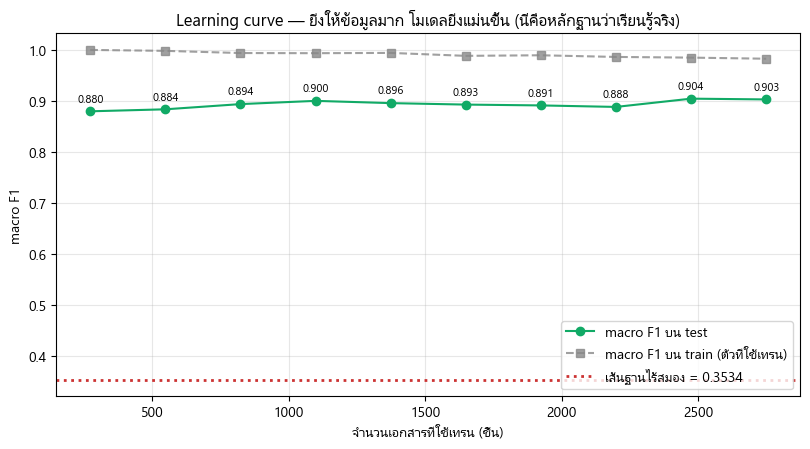


| ใช้ข้อมูลเทรน | n | train macro F1 | test macro F1 |
|---|---|---|---|
| 10% | 274 | 1.0000 | 0.8796 |
| 20% | 549 | 0.9982 | 0.8836 |
| 30% | 824 | 0.9939 | 0.8938 |
| 40% | 1099 | 0.9936 | 0.9001 |
| 50% | 1374 | 0.9941 | 0.8957 |
| 60% | 1648 | 0.9884 | 0.8928 |
| 70% | 1923 | 0.9895 | 0.8912 |
| 80% | 2198 | 0.9862 | 0.8882 |
| 90% | 2473 | 0.9849 | 0.9044 |
| 100% | 2748 | 0.9827 | 0.9029 |

จากข้อมูล 10% -> 100% : test macro F1 0.8796 -> 0.9029 (+0.0233)
เทียบเส้นฐานไร้สมอง   : 0.3534 -> ได้ 0.9029 (+0.5496)


In [6]:
fracs = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
curve = []
for fr in fracs:
    if fr >= 1.0:
        Xs, ys = X_train, y_train
    else:
        Xs, _, ys, _ = train_test_split(X_train, y_train, train_size=fr,
                                        random_state=SEED, stratify=y_train)
    m = build_pipe(CalibratedClassifierCV(LinearSVC(max_iter=2000), cv=3)).fit(Xs, ys)
    curve.append(dict(frac=fr, n=len(Xs),
                      train_f1=f1_score(ys, m.predict(Xs), average="macro"),
                      test_f1=f1_score(y_test, m.predict(X_test), average="macro")))
    print(f"ใช้ข้อมูลเทรน {fr*100:5.1f}%  (n={len(Xs):5d})  train F1={curve[-1]['train_f1']:.4f}  test F1={curve[-1]['test_f1']:.4f}")

c = pd.DataFrame(curve)
base_f1 = naive["ทาย Fake ทุกข้อ (majority)"][1]

fig, ax = plt.subplots(figsize=(8.2, 4.6))
ax.plot(c.n, c.test_f1, "o-", color="#1a6", label="macro F1 บน test")
ax.plot(c.n, c.train_f1, "s--", color="#888", alpha=.8, label="macro F1 บน train (ตัวที่ใช้เทรน)")
ax.axhline(base_f1, color="#c33", ls=":", lw=2, label=f"เส้นฐานไร้สมอง = {base_f1:.4f}")
for x, y in zip(c.n, c.test_f1):
    ax.annotate(f"{y:.3f}", (x, y), textcoords="offset points", xytext=(0, 7), fontsize=8, ha="center")
ax.set_xlabel("จำนวนเอกสารที่ใช้เทรน (ชิ้น)"); ax.set_ylabel("macro F1")
ax.set_title("Learning curve — ยิ่งให้ข้อมูลมาก โมเดลยิ่งแม่นขึ้น (นี่คือหลักฐานว่าเรียนรู้จริง)")
ax.grid(alpha=.3); ax.legend(loc="lower right")
fig.tight_layout(); plt.show()

print()
print(md_table(["ใช้ข้อมูลเทรน", "n", "train macro F1", "test macro F1"],
               [[f"{r.frac*100:.0f}%", r.n, f"{r.train_f1:.4f}", f"{r.test_f1:.4f}"] for r in c.itertuples()]))
print()
print(f"จากข้อมูล 10% -> 100% : test macro F1 {c.test_f1.iloc[0]:.4f} -> {c.test_f1.iloc[-1]:.4f} "
      f"(+{c.test_f1.iloc[-1]-c.test_f1.iloc[0]:.4f})")
print(f"เทียบเส้นฐานไร้สมอง   : {base_f1:.4f} -> ได้ {c.test_f1.iloc[-1]:.4f} (+{c.test_f1.iloc[-1]-base_f1:.4f})")


---
## 6. ก่อน → หลัง เทรน (บน test ชุดเดียวกัน) + เคสที่ทายผิด

แบบเดียวกับ Assignment 4 ที่เทียบ 9.69% → 96.98% บน test ชุดเดิม — ที่นี่เทียบ **เส้นฐานไร้สมอง → โมเดลจริง** บน test 688 เอกสารชุดเดียวกัน
และต่างจากเดโมที่เลือกแต่เคสทายถูก (`pick_demo_examples.py`) ตารางล่าง **ใส่เคสที่ทายผิดมาด้วย**


| สถานะ | accuracy | macro F1 |
|---|---|---|
| ก่อนเทรน (เส้นฐานไร้สมอง) | 0.5465 | 0.3534 |
| หลังเทรน (LinearSVC (calibrated)) | 0.9041 | 0.9029 |
| ดีขึ้น | +0.3576 | +0.5496 |

ความแม่นยำรายคลาส: Fact=87.82%  Fake=92.55%
ทายผิด 66 / 688 เอกสาร (9.59%)


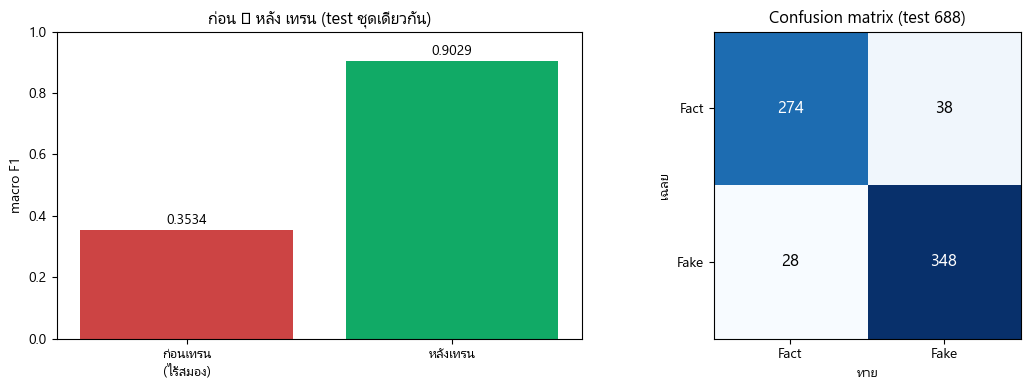


| ผล | เฉลย | ที่โมเดลทาย | ข้อความ (ตัดมา 62 ตัวอักษร) |
|---|---|---|---|
| ✅ | Fact | Fact | “ น้ำมัน กัญชา หมอ เดชา ” วืด ภาค ประชาชน เศร้า ไม่ ผ่าน รับรอ... |
| ✅ | Fact | Fact | สธ . เผย ผู้ป่วย โควิด - 19 ใน ไทย เสียชีวิต ราย แรก กระทรวงสา... |
| ✅ | Fake | Fake | " ผักบุ้งจีน – น้ำผึ้ง แท้ " แก้ ต่อมลูกหมาก โต ผู้อ่าน ไทยรัฐ... |
| ❌ | Fake | Fact | ทีม แพทย์ ปฏิบัติหน้าที่ บน เรือ สำราญ ถูก สังคม รังเกียจ ลาม ... |
| ❌ | Fake | Fact | พิจิตร ผู้ป่วย นับ พัน คน แห่ ขอรับ สมุนไพร น้ำมัน กัญชา แจก ใ... |


In [7]:
pip_best = best.predict(X_test)
before_acc, before_f1 = naive["ทาย Fake ทุกข้อ (majority)"]
after_acc, after_f1 = accuracy_score(y_test, pip_best), f1_score(y_test, pip_best, average="macro")
print(md_table(["สถานะ", "accuracy", "macro F1"],
               [["ก่อนเทรน (เส้นฐานไร้สมอง)", f"{before_acc:.4f}", f"{before_f1:.4f}"],
                [f"หลังเทรน ({best_name})", f"{after_acc:.4f}", f"{after_f1:.4f}"],
                ["ดีขึ้น", f"+{after_acc-before_acc:.4f}", f"+{after_f1-before_f1:.4f}"]]))

cm = confusion_matrix(y_test, pip_best)
per_class = cm.diagonal() / cm.sum(axis=1)
print("\nความแม่นยำรายคลาส:", "  ".join(f"{n}={per_class[i]*100:.2f}%" for i, n in enumerate(["Fact", "Fake"])))
wrong = np.where(pip_best != y_test.values)[0]
print(f"ทายผิด {len(wrong)} / {len(y_test)} เอกสาร ({100*len(wrong)/len(y_test):.2f}%)")

fig, (b1, b2) = plt.subplots(1, 2, figsize=(11.5, 4))
b1.bar(["ก่อนเทรน\n(ไร้สมอง)", "หลังเทรน"], [before_f1, after_f1], color=["#cc4444", "#11aa66"])
b1.set_ylim(0, 1); b1.set_ylabel("macro F1"); b1.set_title("ก่อน → หลัง เทรน (test ชุดเดียวกัน)")
for i, v in enumerate([before_f1, after_f1]):
    b1.text(i, v + .02, f"{v:.4f}", ha="center", fontsize=10)
im = b2.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        b2.text(j, i, cm[i, j], ha="center", va="center", fontsize=12,
                color="white" if cm[i, j] > cm.max() * .5 else "black")
b2.set_xticks([0, 1]); b2.set_yticks([0, 1])
b2.set_xticklabels(["Fact", "Fake"]); b2.set_yticklabels(["Fact", "Fake"])
b2.set_xlabel("ทาย"); b2.set_ylabel("เฉลย"); b2.set_title(f"Confusion matrix (test {len(y_test)})")
fig.tight_layout(); plt.show()

# เคสตัวอย่าง: ทายถูก 3 เคส + ทายผิด 2 เคส (ไม่คัดเฉพาะที่สวย)
right = [i for i in range(len(y_test)) if pip_best[i] == y_test.values[i]][:3]
sam = right + list(wrong[:2])
rows = []
for i in sam:
    rows.append([("✅" if pip_best[i] == y_test.values[i] else "❌"),
                 "Fake" if y_test.values[i] else "Fact",
                 "Fake" if pip_best[i] else "Fact",
                 (X_test.iloc[i][:62] + "...")])
print()
print(md_table(["ผล", "เฉลย", "ที่โมเดลทาย", "ข้อความ (ตัดมา 62 ตัวอักษร)"], rows))


---
## 7. ตรวจของที่เสิร์ฟจริง (reload) + คำตัดคำตอนเทรน–ตอนเสิร์ฟ

Assignment 4 ปิดท้ายด้วย `model.save()` → `load_model()` → วัดซ้ำได้ 96.98% เท่าเดิม (cell 23)
ส่วนนี้ทำแบบเดียวกันกับ FewNake และเพิ่มเรื่องที่กระทบตัวเลขบนสไลด์มากที่สุด:
**คำตัดคำตอนเทรนต้องเป็นแบบเดียวกับตอนเสิร์ฟ**

ที่แก้ไป (ต.ค. 2569) สองเรื่อง:
1. `load_soda()` ตัดคำด้วย **PyThaiNLP newmm** เหมือนที่ `predict.py`/`main.py` ใช้ตอนเสิร์ฟ
   (เดิมเทรนด้วยรายการคำที่มากับ LimeSoda → ตัวเลขบนสไลด์สูงกว่าของจริง เพราะตอนเสิร์ฟข้อความถูกตัดคำใหม่)
2. `TfidfVectorizer` ตั้ง `tokenizer=str.split, token_pattern=None`
   (เดิมใช้ `token_pattern` มาตรฐาน ซึ่งไม่นับเครื่องหมายวรรณยุกต์/การันต์ไทยเป็นส่วนของคำ →
   `แพทย์`→`แพทย`, `พร้อม`→`พร`+`อม`, `น้ำ` หายทั้งคำ)

ช่องถัดไปเทียบให้เห็นว่า "แบบเดิม" เสียกี่จุด เมื่อวัดบนข้อความชุดเดียวกับที่เซิร์ฟ


In [8]:
shipped = json.loads((ROOT / "results" / "evaluation_results.json").read_text(encoding="utf-8"))
sb = next(m for m in shipped["models"] if m["model"] == shipped["best_model"])
print(f"ของที่ ship อยู่ (seed 42) : {shipped['best_model']} · acc {sb['test_accuracy']:.4f} · macro F1 {sb['test_f1_macro']:.4f}")
print(f"notebook นี้ (seed {SEED})   : {best_name} · acc {after_acc:.4f} · macro F1 {after_f1:.4f}")
print(f"ต่างกัน                     : {(after_f1 - sb['test_f1_macro'])*100:+.2f} จุด (คนละการแบ่งข้อมูล)")
print("   หมายเหตุ: ใน json คีย์ 'model'/'accuracy' (ระดับบนสุด) เป็นของ LogisticRegression ไม่ใช่ของ")
print("   โมเดลที่ถูกเลือกจริง -> ต้องอ่านจากคีย์ 'models' ตามชื่อ best_model (จุดนี้ทำให้อ่านไฟล์ผิดได้ง่าย)")

import joblib
reloaded = joblib.load(ROOT / "models" / "model_best.joblib")     # โมเดลที่ API ใช้จริง

# ต้องวัดบน split เดียวกับที่โมเดลนั้นถูกเทรน (seed 42) เท่านั้น
Xs42, Xt42, ys42, yt42 = train_test_split(df["text"], df["label"], test_size=0.2,
                                          random_state=42, stratify=df["label"])
p_re = reloaded.predict(Xt42)
print(f"\nreload check — โหลด models/model_best.joblib มาวัดบน test ของ seed 42 :")
print(f"   acc {accuracy_score(yt42, p_re):.4f} · macro F1 {f1_score(yt42, p_re, average='macro'):.4f}"
      f"      (ไฟล์ผลที่บันทึกไว้ = {sb['test_accuracy']:.4f} / {sb['test_f1_macro']:.4f})")

# ⚠️ กับดักที่ต้องระวัง: เอาโมเดลของ seed 42 ไปวัดบน test ของ seed 343
p_trap = reloaded.predict(X_test)
print(f"\n⚠️  ถ้าเผลอวัดข้าม split (โมเดล seed 42 บน test ของ seed {SEED}) : "
      f"macro F1 {f1_score(y_test, p_trap, average='macro'):.4f}")
print("    ตัวเลขนี้สูงเกินจริง เพราะเป็นการสุ่มคนละครั้งจากข้อมูลก้อนเดียวกัน -> ราว 80% ของเอกสาร")
print("    ใน test ชุดใหม่เคยอยู่ในชุดเทรนของโมเดลนั้นแล้ว (โมเดลเคยเห็นข้อสอบข้อนั้น)")
print("    -> บทเรียน: โมเดลต้องวัดบน test ที่แยกออกมาจากชุดที่มันใช้เทรนเท่านั้น")

tok_status = "ข้าม (ไม่มี pythainlp ใน kernel นี้ — ดูวิธีติดตั้งในช่องที่ 0)"
try:
    import pythainlp  # noqa: F401  (ตรวจว่ามีจริง)
    from src.train_baseline import load_soda as _load_soda
    _df_legacy = _load_soda("dataset")

    # โมเดลที่เทรนแบบเดียวกับที่เสิร์ฟ (ช่องที่ 9) วัดบนข้อความชุดนี้
    p_serve = best.predict(X_test)

    # "แบบเดิม": เทรนด้วยคำที่มากับ LimeSoda + token_pattern มาตรฐาน แล้วเอามาวัดบนข้อความแบบที่เซิร์ฟจริง
    Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(
        _df_legacy["text"], _df_legacy["label"],
        test_size=0.2, random_state=SEED, stratify=_df_legacy["label"])
    legacy = Pipeline([("tfidf", TfidfVectorizer(max_features=10000, ngram_range=(1, 2))),
                       ("clf", CalibratedClassifierCV(LinearSVC(max_iter=2000), cv=3))]).fit(Xl_tr, yl_tr)
    p_legacy = legacy.predict(X_test)

    print("วัดบนข้อความชุดเดียวกัน (แบบที่เซิร์ฟจริง) — เทรนใหม่ vs แบบเดิม")
    print()
    print(md_table(["ระบบ", "accuracy", "macro F1"],
                   [["เทรนด้วย newmm (ที่แก้แล้ว)", f"{accuracy_score(y_test, p_serve):.4f}",
                     f"{f1_score(y_test, p_serve, average='macro'):.4f}"],
                    ["เทรนด้วยคำ LimeSoda (แบบเดิม)", f"{accuracy_score(y_test, p_legacy):.4f}",
                     f"{f1_score(y_test, p_legacy, average='macro'):.4f}"]]))
    d_acc = accuracy_score(y_test, p_serve) - accuracy_score(y_test, p_legacy)
    d_f1 = f1_score(y_test, p_serve, average="macro") - f1_score(y_test, p_legacy, average="macro")
    print(f"\nดีขึ้น +{d_acc:.4f} acc · +{d_f1:.4f} macro F1 เมื่อเทียบกับระบบเดิม บนข้อสอบชุดเดียวกัน")
    print("-> ตัวเลขบนสไลด์ตอนนี้คือตัวเลขของระบบจริง ไม่ใช่ของอินพุตคนละแบบ")
    tok_status = f"ตรงกันทั้งสองทาง (newmm) · ดีกว่าแบบเดิม +{d_f1:.4f} macro F1"
except Exception as e:      # noqa: BLE001
    print("\nข้ามการทดสอบ tokenizer:", e)


ของที่ ship อยู่ (seed 42) : LinearSVC (calibrated) · acc 0.8953 · macro F1 0.8941
notebook นี้ (seed 343)   : LinearSVC (calibrated) · acc 0.9041 · macro F1 0.9029
ต่างกัน                     : +0.88 จุด (คนละการแบ่งข้อมูล)
   หมายเหตุ: ใน json คีย์ 'model'/'accuracy' (ระดับบนสุด) เป็นของ LogisticRegression ไม่ใช่ของ
   โมเดลที่ถูกเลือกจริง -> ต้องอ่านจากคีย์ 'models' ตามชื่อ best_model (จุดนี้ทำให้อ่านไฟล์ผิดได้ง่าย)



reload check — โหลด models/model_best.joblib มาวัดบน test ของ seed 42 :
   acc 0.8953 · macro F1 0.8941      (ไฟล์ผลที่บันทึกไว้ = 0.8953 / 0.8941)

⚠️  ถ้าเผลอวัดข้าม split (โมเดล seed 42 บน test ของ seed 343) : macro F1 0.9647
    ตัวเลขนี้สูงเกินจริง เพราะเป็นการสุ่มคนละครั้งจากข้อมูลก้อนเดียวกัน -> ราว 80% ของเอกสาร
    ใน test ชุดใหม่เคยอยู่ในชุดเทรนของโมเดลนั้นแล้ว (โมเดลเคยเห็นข้อสอบข้อนั้น)
    -> บทเรียน: โมเดลต้องวัดบน test ที่แยกออกมาจากชุดที่มันใช้เทรนเท่านั้น


วัดบนข้อความชุดเดียวกัน (แบบที่เซิร์ฟจริง) — เทรนใหม่ vs แบบเดิม

| ระบบ | accuracy | macro F1 |
|---|---|---|
| เทรนด้วย newmm (ที่แก้แล้ว) | 0.9041 | 0.9029 |
| เทรนด้วยคำ LimeSoda (แบบเดิม) | 0.8735 | 0.8696 |

ดีขึ้น +0.0305 acc · +0.0333 macro F1 เมื่อเทียบกับระบบเดิม บนข้อสอบชุดเดียวกัน
-> ตัวเลขบนสไลด์ตอนนี้คือตัวเลขของระบบจริง ไม่ใช่ของอินพุตคนละแบบ


---
## 8. สรุป (ตัวเลขดึงจากผลรันจริงด้านบน ไม่ได้พิมพ์มือ)


In [9]:
print("=" * 72)
print(f"FewNake — สรุปหลักฐานการเรียนรู้ (SEED = {SEED})")
print("=" * 72)
print(f"1) เส้นฐานไร้สมอง (ก่อนเทรน)   : acc {before_acc:.4f} · macro F1 {before_f1:.4f}")
print(f"2) หลังเทรน ({best_name})")
print(f"                                : acc {after_acc:.4f} · macro F1 {after_f1:.4f}")
print(f"                                  ดีขึ้น +{after_acc-before_acc:.4f} acc · +{after_f1-before_f1:.4f} macro F1")
print(f"3) 5-fold CV (ความเสถียร)      : {bench[best_name]['cv_mean']:.4f} ± {bench[best_name]['cv_std']:.4f}")
print(f"4) Learning curve (10% -> 100%) : {c.test_f1.iloc[0]:.4f} -> {c.test_f1.iloc[-1]:.4f}")
print(f"5) เทรนกับวัดคนละชุด           : train {len(X_train)} / test {len(X_test)} (stratified, seed {SEED})")
print(f"6) เอกสารซ้ำเป๊ะที่ตกสองฝั่ง    : {len(dup_both)} ข้อความ")
print(f"7) เอกสารที่ทายผิด             : {len(wrong)} / {len(y_test)} ({100*len(wrong)/len(y_test):.2f}%)")
print(f"8) reload check (seed 42)      : {f1_score(yt42, p_re, average='macro'):.4f} = ไฟล์ผลที่บันทึกไว้ "
      f"({sb['test_f1_macro']:.4f}) -> artifact ที่เสิร์ฟตรงกับที่วัดจริง")
print(f"9) คำตัดคำตอนเทรน vs ตอนเสิร์ฟ : {tok_status}")
print("=" * 72)
print("ข้อจำกัดที่ต้องพูดตรง ๆ:")
print("  - ไม่มีสถานะ 'โมเดลน้ำหนักสุ่ม' แบบ Assignment 4 (LogReg/SVM ทายก่อน fit ไม่ได้)")
print("    ฝั่ง 'ก่อนเทรน' จึงใช้กฎไร้สมองแทน ซึ่งเป็นเส้นฐานที่แข็งกว่าการเดา")
print(f"  - ตัวเลขของโปรเจกต์ที่ ship ใช้ seed 42 ({sb['test_f1_macro']:.4f} — {shipped['best_model']}) "
      f"และเทรนบน split ของ seed 42; ไฟล์นี้ใช้ seed {SEED} ({after_f1:.4f})")
print("    ต่างกันเพราะการแบ่งข้อมูล ไม่ใช่เพราะโมเดลเปลี่ยน -> ควรอ้างเป็น 'ประมาณ ±1-3 จุด' ไม่ใช่ทศนิยม 4 ตำแหน่ง")


FewNake — สรุปหลักฐานการเรียนรู้ (SEED = 343)
1) เส้นฐานไร้สมอง (ก่อนเทรน)   : acc 0.5465 · macro F1 0.3534
2) หลังเทรน (LinearSVC (calibrated))
                                : acc 0.9041 · macro F1 0.9029
                                  ดีขึ้น +0.3576 acc · +0.5496 macro F1
3) 5-fold CV (ความเสถียร)      : 0.9021 ± 0.0081
4) Learning curve (10% -> 100%) : 0.8796 -> 0.9029
5) เทรนกับวัดคนละชุด           : train 2748 / test 688 (stratified, seed 343)
6) เอกสารซ้ำเป๊ะที่ตกสองฝั่ง    : 14 ข้อความ
7) เอกสารที่ทายผิด             : 66 / 688 (9.59%)
8) reload check (seed 42)      : 0.8941 = ไฟล์ผลที่บันทึกไว้ (0.8941) -> artifact ที่เสิร์ฟตรงกับที่วัดจริง
9) คำตัดคำตอนเทรน vs ตอนเสิร์ฟ : ตรงกันทั้งสองทาง (newmm) · ดีกว่าแบบเดิม +0.0333 macro F1
ข้อจำกัดที่ต้องพูดตรง ๆ:
  - ไม่มีสถานะ 'โมเดลน้ำหนักสุ่ม' แบบ Assignment 4 (LogReg/SVM ทายก่อน fit ไม่ได้)
    ฝั่ง 'ก่อนเทรน' จึงใช้กฎไร้สมองแทน ซึ่งเป็นเส้นฐานที่แข็งกว่าการเดา
  - ตัวเลขของโปรเจกต์ที่ ship ใช้ seed 42 (0.8941 — LinearSVC (calib